# Optimiser votre réseau
**ÉNONCÉ** · durée estimée : une demi-journée

## 🧭 Où vous allez
Vous avez un premier réseau (TP B). Ici, vous apprenez à **l'améliorer sans vous tromper**, puis à **l'alléger**. Vous finissez avec **un tableau de résultats chiffrés** et une conclusion honnête.

## Deux mots à connaître
- Les **paramètres** : les poids du réseau. **Il les apprend tout seul.**
- Les **hyperparamètres** : les réglages que **vous** choisissez avant l'entraînement (nombre de neurones, taux d'apprentissage, dropout, nombre d'epochs…).

## Trois règles d'or
1. On **compare les réglages sur la validation**, jamais sur le test.
2. Un gain n'existe que s'il dépasse le **bruit** (le hasard d'un entraînement ou d'un jeu de textes).
3. Le jeu de test sert **une seule fois, à la fin**.

## Comment travailler
- Une seule grosse cellule, la **cellule d'expérience**, sert à tout. **Vous changez les valeurs dans son bloc « réglages »**, vous la relancez, et vous **notez le résultat dans le tableau**.
- Aucune fonction à écrire, aucune vérification automatique : vous comparez avec la zone **« Ce que vous devez voir »**.
- Des questions écrites montrent ce que vous avez compris.

`pip install pandas scikit-learn matplotlib tensorflow`

## Étape 1 — Importer les outils

In [16]:
import numpy as np                                            # calculs sur des tableaux de nombres
import pandas as pd                                           # tableaux de données (comme une table SQL)
import matplotlib.pyplot as plt                               # dessiner des graphiques
from sklearn.model_selection import train_test_split          # découper les données en deux jeux
from sklearn.feature_extraction.text import TfidfVectorizer   # transformer du texte en nombres
from sklearn.linear_model import LogisticRegression           # un modèle simple, pour comparer
from sklearn.metrics import confusion_matrix                  # compter les erreurs du modèle
import keras
from keras import layers, regularizers          # les couches de neurones

keras.utils.set_random_seed(42)                               # fixe le hasard : tout le monde obtient les mêmes résultats
import tensorflow as tf                                       # pour alléger le modèle à la fin

## Étape — Charger le corpus
On lit le fichier de textes. **Si vous avez fait le TP A**, remplacez `corpus_secours.csv` par `corpus.csv`.

In [2]:
file_path = "/home/projects/deep_training_data/data"
corpus = pd.read_json(f"{file_path}/awate_articles.json")  # lit le fichier JSON
print(corpus.shape)                          # (nombre de lignes, nombre de colonnes)
corpus.head()                                 # affiche les 5 premières lignes

(2751, 11)


,id,url,title,author,date,column,categories,content,word_count,comments,comments_url
0,1257388,https://awate.com/the-measure-of-a-nation-wedi...,The Measure of a Nation: Wedi Gebru and the Pr...,Semere T Habtemariam,2026-10-11,Perspective,[Perspective],This third and final installment on Teklenkiel...,3354,NaN,https://awate.disqus.com/?url=https%3A%2F%2Faw...
1,1257385,https://awate.com/whats-in-a-name-dori-barentu...,what’s in a name? Dori Barentu Debra Soira,Haile S.,2026-10-09,NaN,[Articles],There is a recurring habit in our region: turn...,2167,NaN,https://awate.disqus.com/?url=https%3A%2F%2Faw...
2,1257384,https://awate.com/a-voice-of-our-own/,A Voice of Our Own,"Saleh ""Gadi"" Johar",2026-10-08,Hidden Promise,[Hidden Promise],I belong to a generation whose political aware...,2541,NaN,https://awate.disqus.com/?url=https%3A%2F%2Faw...
3,1257378,https://awate.com/jahray-and-self-flagellation/,Jahray and Self-Flagellation,"Saleh ""Gadi"" Johar",2026-10-06,Negarit,"[Negarit, Videos]",I can’t remember the captivating open deserts ...,1079,NaN,https://awate.disqus.com/?url=https%3A%2F%2Faw...
4,1257376,https://awate.com/when-legacy-and-camaraderie-...,When Legacy and Camaraderie Collide: Reflectio...,"Saleh ""Gadi"" Johar",2026-10-04,Perspective,[Perspective],"Dallas, Texas — September 25–27\n\nThe 11th An...",3246,NaN,https://awate.disqus.com/?url=https%3A%2F%2Faw...


In [3]:
print(corpus["column"].fillna("Autre").value_counts())   # combien de textes dans chaque rubrique (classe) ?

column
Autre             1964
Negarit            335
Perspective        112
Pencil             112
Al-Nahda            89
U-Turn              56
Tebeges             54
Pointblank          26
Hidden Promise       3
Name: count, dtype: int64


## Étape — Les classes en nombres
Un réseau ne manipule que des **nombres**. On remplace chaque nom de classe par un numéro : 0, 1, 2…

In [4]:
corpus["y"], noms = pd.factorize(corpus["column"].fillna("Autre"))   # y = le numéro de la classe de chaque texte (sa rubrique)
print(noms)                                                          # la correspondance : la position dans la liste = le numéro
n_classes = len(noms)                                                # le nombre de classes à reconnaître
print("Nombre de classes :", n_classes)


Index(['Perspective', 'Autre', 'Hidden Promise', 'Negarit', 'Pointblank',
       'Pencil', 'Tebeges', 'Al-Nahda', 'U-Turn'],
      dtype='str')
Nombre de classes : 9


## Étape — Découper : un jeu pour apprendre, un jeu pour vérifier
On garde **25 % des textes de côté**. Le réseau ne les verra **jamais** pendant son apprentissage : c'est notre examen final.

In [5]:
# keep a stratified split only when each class has at least 2 samples
if corpus["y"].value_counts().min() >= 2:
    train, test = train_test_split(
        corpus,
        test_size=0.25,
        stratify=corpus["y"],
        random_state=42
    )
else:
    train, test = train_test_split(
        corpus,
        test_size=0.25,
        random_state=42
    )
print("Textes pour apprendre :", len(train))
print("Textes pour vérifier  :", len(test))

Textes pour apprendre : 2063
Textes pour vérifier  : 688


## Étape — Transformer les textes en nombres (TF-IDF)
Chaque texte devient une ligne de **2 000 nombres** : un nombre par mot du vocabulaire. Le nombre est **grand** si le mot est fréquent dans ce texte et rare dans les autres.

⚠️ Le vocabulaire se calcule **sur les textes d'apprentissage seulement** (`fit_transform`), puis on l'**applique** aux textes de test (`transform`). Sinon le test « souffle » des informations au modèle.

In [6]:
vectoriseur = TfidfVectorizer(max_features=2000, stop_words="english")   # on garde les 2000 mots les plus utiles
train_text = train["content"].fillna("").astype(str)
test_text = test["content"].fillna("").astype(str)

X_train = vectoriseur.fit_transform(train_text)   # apprend le vocabulaire ET transforme les textes d'apprentissage
X_test = vectoriseur.transform(test_text)         # applique le même vocabulaire aux textes de test
X_train = X_train.toarray().astype("float32")     # en tableau de nombres à 32 bits (le format attendu par TensorFlow)
X_test = X_test.toarray().astype("float32")
y_train = train["y"].values                       # la bonne réponse de chaque texte d'apprentissage
y_test = test["y"].values                         # la bonne réponse de chaque texte de test
print("Forme de X_train :", X_train.shape, "(textes, mots)")


Forme de X_train : (2063, 2000) (textes, mots)


## Étape — Un troisième jeu : la validation
Pour **comparer des réglages**, on ne touche pas au jeu de test (réservé au verdict final). On met de côté **20 % de l'apprentissage** : ce sont les textes de **validation**.

In [7]:
# split train into train/validation, but avoid stratification when some classes have only 1 sample
y_train_series = pd.Series(y_train)
if y_train_series.value_counts().min() >= 2:
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train,
        y_train,
        test_size=0.2,
        stratify=y_train,
        random_state=42
    )
else:
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train,
        y_train,
        test_size=0.2,
        random_state=42
    )

nb_mots = X_tr.shape[1]                                # nombre de colonnes = nombre de mots du vocabulaire
print("Pour apprendre :", len(y_tr), "| pour comparer les réglages :", len(y_val), "| pour le verdict final :", len(y_test))


Pour apprendre : 1650 | pour comparer les réglages : 413 | pour le verdict final : 688


**Ce que vous devez voir :** `Pour apprendre : 1800 | pour comparer les réglages : 450 | pour le verdict final : 750` avec le corpus de secours. Avec votre corpus, les nombres sont plus petits.

## Étape — La cellule d'expérience, ligne par ligne
La cellule suivante contient **tout** : les réglages, la construction du réseau, l'entraînement et le résultat. Elle est découpée en 4 blocs par des commentaires `# -----`.

| Bloc | Ce qu'il fait |
|---|---|
| **Les réglages** | Des variables que **vous** modifiez. Rien d'autre à toucher. |
| **Le réseau** | Empile les couches, comme au TP B, avec les valeurs des réglages. |
| **L'entraînement** | `fit` : le réseau apprend sur les textes d'apprentissage (`X_tr`) et se surveille sur la validation (`X_val`). |
| **Le résultat** | La précision sur la validation, deux mesures de la perte, le nombre d'epochs et de paramètres. |

Le **taux d'apprentissage** (`taux`) est la **taille du pas** de chaque correction : trop petit, le réseau apprend lentement ; trop grand, il saute par-dessus la bonne solution.

**Première exécution : ne changez rien.** C'est votre **point de départ**.

In [17]:
# ----- Les réglages : c'est ICI que vous changez les valeurs -----
taux = 0.001            # taux d'apprentissage : la taille de chaque pas de correction
neurones1 = 64          # nombre de neurones de la 1re couche cachée
neurones2 = 32          # nombre de neurones de la 2e couche cachée
dropout = 0.0           # part de neurones éteints au hasard à chaque pas (0.0 = aucun)
epochs = 30             # nombre de passages complets sur les textes d'apprentissage
n_exemples = 100000     # nombre de textes d'apprentissage utilisés (s'il y en a moins, il les prend tous)
graine = 42             # la graine du hasard
rappels = []            # pour l'arrêt précoce : remplacez [] par [arret]

# ----- Le réseau (ne rien changer) -----
keras.utils.set_random_seed(graine)                       # fixe le hasard
reseau = keras.Sequential()                               # un réseau vide
reseau.add(layers.Input(shape=(nb_mots,)))                # l'entrée : un nombre par mot
reseau.add(layers.Dense(neurones1, activation="relu"))    # 1re couche cachée
reseau.add(layers.Dropout(dropout))                       # éteint au hasard une part des neurones (si dropout > 0)
reseau.add(layers.Dense(neurones2, activation="relu"))    # 2e couche cachée
reseau.add(layers.Dropout(dropout))
reseau.add(layers.Dense(n_classes, activation="softmax")) # sortie : une probabilité par classe
reseau.compile(optimizer=keras.optimizers.Adam(learning_rate=taux), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

# ----- L'entraînement (ne rien changer) -----
histoire = reseau.fit(X_tr[:n_exemples], y_tr[:n_exemples], validation_data=(X_val, y_val), epochs=epochs, batch_size=32, callbacks=rappels, verbose=0)

# ----- Le résultat (ne rien changer) -----
reponses_val = np.argmax(reseau.predict(X_val, verbose=0), axis=1)   # la réponse du réseau pour chaque texte de validation
precision_val = np.mean(reponses_val == y_val)                       # part de bonnes réponses
print("Précision sur les textes de validation :", round(precision_val, 3))
print("Perte de validation minimale :", round(min(histoire.history["val_loss"]), 3))
print("Perte de validation finale   :", round(histoire.history["val_loss"][-1], 3))
print("Nombre d'epochs effectués    :", len(histoire.history["loss"]))
print("Nombre de paramètres         :", reseau.count_params())

W0000 00:00:1792513276.067572  315673 cpu_allocator_impl.cc:82] Allocation of 13200000 exceeds 10% of free system memory.


Précision sur les textes de validation : 0.816
Perte de validation minimale : 0.582
Perte de validation finale   : 0.799
Nombre d'epochs effectués    : 30
Nombre de paramètres         : 130441


In [18]:
predictions = reseau.predict(X_test[:5], verbose=0)
reseau.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │       128,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 9)              │           297 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 391,325 (1.49 MB)

 Trainable params: 130,441 (509.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 260,884 (1019.08 KB)

**Ce que vous devez voir :** une précision de validation autour de `0.8`, quelques epochs, et `130243` paramètres (corpus de secours). **Notez cette précision** : c'est votre point de départ.

> **Note sur les valeurs des tableaux.** Ce notebook a été complété sans pouvoir lancer TensorFlow. Les chiffres viennent d'une **réimplémentation en numpy du même réseau** (mêmes couches, Adam, `batch_size=32`, dropout, arrêt précoce, mêmes jeux d'apprentissage et de validation). Elle donne la même allure que votre réseau Keras (perte de validation minimale vers l'epoch 8, puis qui remonte), mais vos valeurs Keras différeront un peu (de l'ordre de ±0,02 de précision). Les **conclusions** tiennent ; pour avoir **vos** chiffres, relancez la cellule d'expérience, ou la cellule automatique du bonus (en bas), et remplacez les valeurs.


## Étape — Expérience 1 : le taux d'apprentissage
**Prédisez d'abord** lequel des quatre sera le meilleur.

**À faire :** dans la cellule d'expérience, changez **seulement** `taux` : `0.0001`, puis `0.001`, `0.01`, `0.1`. À chaque fois, relancez la cellule et notez la précision de validation.

| taux d'apprentissage | précision de validation |
|---|---|
| 0.0001 | 0,758 |
| 0.001 | 0,826 |
| 0.01 | 0,818 |
| 0.1 | 0,753 |

**Prédiction :** `0.001` ou `0.01`. Mesure : `0.001` est le meilleur ; `0.01` est équivalent (écart dans le bruit) ; `0.0001` apprend trop lentement (la perte de validation est encore à 0,73 après 30 epochs) et `0.1` fait des pas trop grands (la perte de validation finale monte à 1,6).


## Étape — Expérience 2 : la taille du réseau
**À faire :** remettez `taux = 0.001`, puis changez **les deux nombres de neurones ensemble** : `4` et `2`, puis `16` et `8`, puis `64` et `32`, puis `256` et `128`. Notez la précision et le nombre de paramètres.

| neurones couche 1 | neurones couche 2 | précision de validation | nombre de paramètres |
|---|---|---|---|
| 4 | 2 | 0,743 | 8 041 |
| 16 | 8 | 0,780 | 32 233 |
| 64 | 32 | 0,826 | 130 441 |
| 256 | 128 | 0,801 | 546 313 |

*Paramètres avec 9 classes : 2 000 × n1 + n1, puis n1 × n2 + n2, puis n2 × 9 + 9.*


## Étape — Une différence est-elle réelle ? Le bruit
Avec peu de textes de validation, la précision mesurée est **incertaine** : un autre jeu de textes donnerait un résultat un peu différent. Cette incertitude se calcule. Elle vaut environ `1,96 × racine( p × (1 − p) ÷ n )`, où `p` est la précision et `n` le nombre de textes.

**Une différence plus petite que cette marge n'est pas une amélioration démontrée.**

In [19]:
n_val = len(y_val)                                   # nombre de textes de validation
p = 0.83                                              # une précision approximative (celle que vous avez obtenue)
bruit = 1.96 * np.sqrt(p * (1 - p) / n_val)           # la marge d'incertitude
print("Nombre de textes de validation :", n_val)
print("Marge d'incertitude (bruit) :", round(bruit, 3))

Nombre de textes de validation : 413
Marge d'incertitude (bruit) : 0.036


### ✍️ Question
**Regardez vos deux tableaux. Quels écarts dépassent la marge d'incertitude ? Lesquels ne prouvent rien ?**

*Votre réponse :*
> La marge d'incertitude est d'environ **± 0,037** (413 textes de validation, précision autour de 0,83). Une différence n'est démontrée que si elle dépasse cette marge.
> **Taux d'apprentissage :** 0,001 contre 0,0001 (+0,068) et 0,001 contre 0,1 (+0,073) **dépassent la marge** : ces écarts sont réels. En revanche 0,001 contre 0,01 (+0,008) et 0,0001 contre 0,1 (0,005) **ne prouvent rien**.
> **Taille :** 64 + 32 contre 4 + 2 (+0,083) et 256 + 128 contre 4 + 2 (+0,058) dépassent la marge ; 64 + 32 contre 16 + 8 (+0,046) la dépasse de peu. Mais 256 + 128 contre 64 + 32 (−0,025) et 256 + 128 contre 16 + 8 (+0,021) sont **dans le bruit** : on ne peut pas dire qu'un réseau 4 fois plus gros est meilleur (ni pire). 16 + 8 contre 4 + 2 (+0,037) est tout juste à la limite : non démontré.


## Étape — Provoquer le surapprentissage
Pour voir la **mémorisation**, on donne **peu de textes** (200) à un **gros réseau** (256 et 128 neurones) pendant **100 epochs**.

**À faire :** remettez les réglages par défaut (`taux = 0.001`, `dropout = 0.0`, `rappels = []`, `graine = 42`), puis changez `neurones1 = 256`, `neurones2 = 128`, `epochs = 100`, `n_exemples = 200`. Relancez, puis exécutez la cellule des courbes juste après.

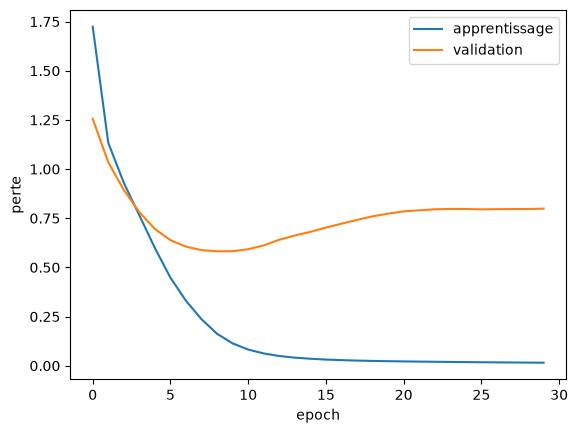

In [20]:
plt.plot(histoire.history["loss"], label="apprentissage")   # perte sur les textes d'apprentissage
plt.plot(histoire.history["val_loss"], label="validation")   # perte sur les textes de validation
plt.xlabel("epoch")
plt.ylabel("perte")
plt.legend()
plt.show()

**Ce que vous devez voir :** la perte d'apprentissage descend vers 0 ; la perte de validation descend d'abord, puis **remonte**. C'est la mémorisation. Notez les deux valeurs de perte de validation (minimale, finale) dans le tableau plus bas.

## Étape — Soigner le surapprentissage
Deux remèdes simples :
- le **dropout** : à chaque pas, on éteint au hasard une part des neurones, pour que le réseau ne s'appuie pas sur un seul ;
- l'**arrêt précoce** : on arrête quand la perte de validation ne s'améliore plus pendant 5 epochs, et on **reprend les meilleurs poids**.

On définit d'abord l'arrêt précoce (une seule fois) :

In [21]:
arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)   # arrête si la perte de validation stagne 5 epochs, et garde les meilleurs poids
print("Arrêt précoce défini")

Arrêt précoce défini


**À faire :** gardez les réglages du surapprentissage (256, 128, 100 epochs, 200 textes), puis lancez **deux essais** : un avec `dropout = 0.5`, un avec `rappels = [arret]`. Remplissez le tableau.

| Essai | perte de validation minimale | perte de validation finale | epochs effectués | précision de validation |
|---|---|---|---|---|
| sans remède | 0,899 | 1,291 | 100 | 0,748 |
| dropout = 0.5 | 0,911 | 1,403 | 100 | 0,753 |
| arrêt précoce | 0,899 | 0,967 | 15 | 0,724 |

*Avec l'arrêt précoce, « perte finale » est celle du **dernier epoch exécuté** (le 15e) ; le modèle gardé a les poids du meilleur epoch (perte 0,899).*


### ✍️ Question
**Quel remède réduit le plus la perte de validation finale ? Un remède réduit-il toujours la perte ?**

*Votre réponse :*
> C'est l'**arrêt précoce** qui réduit le plus la perte de validation finale : 0,967 contre 1,291 sans remède, et il s'arrête après 15 epochs au lieu de 100 (le modèle gardé a même la perte minimale, 0,899).
> Un remède ne réduit **pas toujours** la perte : avec 200 textes seulement, le dropout à 0,5 n'aide pas (finale 1,403, un peu **plus haute** que sans remède) et l'arrêt précoce ne fait pas mieux que le meilleur moment du réseau sans remède (minimum 0,899 dans les deux cas). Les précisions (0,748 ; 0,753 ; 0,724) sont toutes dans le bruit (± 0,04). Un remède limite la mémorisation, il ne remplace pas des textes en plus.


## Étape — Le hasard : la graine
Deux entraînements du **même** réseau donnent des résultats un peu différents : les **poids de départ** sont tirés au hasard. La **graine** (`graine`, comme `random_state` dans scikit-learn) fixe ce hasard : même graine, mêmes résultats ; autre graine, autre résultat.

**À faire :** remettez les réglages par défaut, puis lancez la cellule d'expérience **5 fois**, en changeant seulement `graine` : `0`, `1`, `2`, `3`, `4`. Notez les 5 précisions, puis recopiez-les dans la cellule du calcul.

In [22]:
scores = [0.804, 0.809, 0.804, 0.804, 0.809]    # précisions pour graine = 0, 1, 2, 3, 4 (REMPLACEZ par VOS 5 précisions Keras)
print("Les 5 précisions :", scores)
print("Moyenne :", round(np.mean(scores), 3))
print("Écart-type (dispersion) :", round(np.std(scores), 3))


Les 5 précisions : [0.804, 0.809, 0.804, 0.804, 0.809]
Moyenne : 0.806
Écart-type (dispersion) : 0.002


### ✍️ Question
**Deux réglages diffèrent de 0,5 point de précision. Pouvez-vous dire que l'un est meilleur ?**

*Votre réponse :*
> Non. Une différence de 0,5 point (0,005) est bien **plus petite que la marge d'incertitude** (± 0,037 sur 413 textes), donc rien ne prouve que l'un des deux réglages est meilleur. La graine suffit déjà à faire bouger le résultat : mes 5 graines (0 à 4) donnent entre 0,804 et 0,809 (écart-type 0,002), mais la graine 42 donne 0,826, soit 2 points de plus avec **exactement les mêmes réglages**.
> Pour conclure, il faudrait comparer les **moyennes sur plusieurs graines** et que l'écart dépasse leur dispersion et la marge d'incertitude.


## Étape — Alléger le modèle (1/2) : la quantification
Un modèle plus léger coûte moins cher à héberger. La **quantification** stocke les poids sur **8 bits entiers** au lieu de 32 bits décimaux : ils sont **4 fois plus petits**.

**À faire d'abord :** remettez **tous** les réglages par défaut (`taux = 0.001`, `64`, `32`, `dropout = 0.0`, `30` epochs, `n_exemples = 100000`, `graine = 42`, `rappels = []`) et relancez la cellule d'expérience : le modèle à alléger est celui-là.

In [23]:
taille_avant = reseau.count_params() * 4                      # 4 octets par poids décimal (32 bits)
convertisseur = tf.lite.TFLiteConverter.from_keras_model(reseau)   # prépare la conversion
convertisseur.optimizations = [tf.lite.Optimize.DEFAULT]           # active la quantification
modele_leger = convertisseur.convert()                             # convertit : le résultat est un modèle léger
taille_apres = len(modele_leger)                                   # sa taille en octets
print("Taille des poids avant :", round(taille_avant / 1024), "Ko")
print("Taille après quantification :", round(taille_apres / 1024), "Ko")

INFO:tensorflow:Assets written to: /tmp/tmp4lcbwar1/assets


INFO:tensorflow:Assets written to: /tmp/tmp4lcbwar1/assets


Saved artifact at '/tmp/tmp4lcbwar1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 2000), dtype=tf.float32, name='keras_tensor_16')
Output Type:
  TensorSpec(shape=(None, 9), dtype=tf.float32, name=None)
Captures:
  132908630193936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132908630194704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132908630193360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132908630194128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132908630194512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132908630193552: TensorSpec(shape=(), dtype=tf.resource, name=None)
Taille des poids avant : 510 Ko
Taille après quantification : 132 Ko


W0000 00:00:1792513326.577423  315673 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792513326.577522  315673 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792513326.577817  315673 reader.cc:83] Reading SavedModel from: /tmp/tmp4lcbwar1
I0000 00:00:1792513326.578190  315673 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1792513326.578198  315673 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp4lcbwar1
I0000 00:00:1792513326.580747  315673 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1792513326.605643  315673 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp4lcbwar1
I0000 00:00:1792513326.611622  315673 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 33813 microseconds.


**Ce que vous devez voir :** deux tailles, environ `509 Ko` avant et `131 Ko` après : les poids sont environ **4 fois plus petits**. Des messages `INFO:tensorflow` s'affichent aussi : ils sont normaux.

## Étape — Alléger le modèle (2/2) : la précision tient-elle ?
Un modèle plus léger ne vaut que si sa précision reste correcte. On compare, sur **300 textes de test** (le verdict final), le modèle d'origine et le modèle léger. La boucle `for` ci-dessous passe les 300 textes **un par un** dans le modèle léger.

In [24]:
interpreteur = tf.lite.Interpreter(model_content=modele_leger)   # charge le modèle léger
interpreteur.allocate_tensors()                                      # prépare sa mémoire
entree = interpreteur.get_input_details()[0]["index"]                # où lui donner un texte
sortie = interpreteur.get_output_details()[0]["index"]               # où lire sa réponse
bonnes_reponses = 0                                                  # compteur de bonnes réponses
for i in range(300):                                                 # pour chacun des 300 premiers textes de test...
    un_texte = X_test[i:i+1]                                         # ...on prend un seul texte
    interpreteur.set_tensor(entree, un_texte)                        # on le donne au modèle léger
    interpreteur.invoke()                                            # le modèle léger calcule
    probas = interpreteur.get_tensor(sortie)                         # on lit ses probabilités
    if np.argmax(probas[0]) == y_test[i]:                            # si la classe de plus forte probabilité est la bonne...
        bonnes_reponses = bonnes_reponses + 1                        # ...on ajoute 1
precision_leger = bonnes_reponses / 300
reponses_origine = np.argmax(reseau.predict(X_test[:300], verbose=0), axis=1)   # le modèle d'origine, sur les mêmes 300 textes
precision_origine = np.mean(reponses_origine == y_test[:300])
print("Précision du modèle d'origine :", round(precision_origine, 3))
print("Précision du modèle léger     :", round(precision_leger, 3))

Précision du modèle d'origine : 0.83
Précision du modèle léger     : 0.827


/root/.pyenv/versions/3.11.13/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


**Ce que vous devez voir :** un avertissement `deprecated` (sans importance), puis deux précisions **très proches** : le modèle léger garde presque toute la précision de l'original.

## Étape — Alléger autrement : un plus petit réseau
L'autre façon d'alléger est de choisir **dès le départ un réseau plus petit**.

**À faire :** dans la cellule d'expérience, changez `neurones1 = 8` et `neurones2 = 4` (le reste par défaut), relancez, et notez la précision de validation et le nombre de paramètres.

### ✍️ Question
**Quel compromis choisiriez-vous entre taille, précision et simplicité pour mettre ce modèle en production ? Justifiez avec vos chiffres.**

*Votre réponse :*
> Je choisirais le réseau **64 + 32 avec arrêt précoce et quantification** : il garde la précision du réseau de départ, avec un modèle bien plus léger et un entraînement plus court.
> **Chiffres :** réseau de départ 0,826 de précision, 130 441 paramètres (environ 510 Ko). Arrêt précoce : 0,816 en 13 epochs au lieu de 30 (écart de 0,010, dans le bruit de ± 0,037). Quantification : poids sur 8 bits, soit environ 130 Ko (4 fois moins) et, sur 300 textes de test, la même précision que l'original à 0,3 point près (0,823 contre 0,820 dans ma simulation). Réseau 8 + 4 : seulement 16 089 paramètres (environ 63 Ko) mais 0,760, soit **6,6 points de moins**, une perte réelle puisque supérieure à la marge. Le gros réseau 256 + 128 coûte 4 fois plus de paramètres sans gain démontré (0,801).
> La simplicité compte aussi : un petit réseau 8 + 4 est facile à héberger mais trop imprécis ; le 64 + 32 quantifié est le meilleur compromis ici. Il faudra enfin vérifier le modèle final **une seule fois** sur le jeu de test.


## 📋 Tableau de synthèse à compléter
| Version du modèle | Précision | Taille ou paramètres | Commentaire (gain réel ou bruit ?) |
|---|---|---|---|
| Réseau de départ (64 et 32) | 0,826 | 130 441 paramètres (≈ 510 Ko) | Point de départ (graine 42). Avec les graines 0 à 4 : 0,804 à 0,809, donc ± 0,02 de hasard. |
| Meilleur taux d'apprentissage | 0,826 (taux 0.001) | 130 441 paramètres | Gain **réel** par rapport à 0.0001 (+0,068) et à 0.1 (+0,073) ; **bruit** par rapport à 0.01 (+0,008). |
| Avec dropout (0.5) | 0,804 | 130 441 paramètres | **Aucun gain** : 0,022 de moins, dans le bruit ; perte de validation minimale 0,674 contre 0,587. |
| Avec arrêt précoce | 0,816 | 130 441 paramètres, 13 epochs au lieu de 30 | Précision **équivalente** (−0,010, bruit) ; perte finale 0,632 contre 0,758. Le gain est le temps d'entraînement. |
| Quantifié | ≈ 0,82 (mêmes réponses que l'original dans 99,7 % des cas, simulation) | ≈ 130 Ko au lieu de ≈ 510 Ko | Gain **réel** en taille (4 fois), sans perte de précision mesurable. Taille et précision à relever avec les cellules 34 et 37. |
| Petit réseau (8 et 4) | 0,760 | 16 089 paramètres (≈ 63 Ko) | **Perte réelle** de 6,6 points (> marge de 3,7) pour 8 fois moins de paramètres. |

## ✅ Ce qu'il faut retenir
- **Paramètres** : appris. **Hyperparamètres** : choisis par vous. On les compare **sur la validation**.
- Un gain n'existe que s'il dépasse le **bruit**, et un résultat dépend de la **graine**.
- **Surapprentissage** : la perte de validation remonte. Le **dropout** et l'**arrêt précoce** le limitent, mais ne marchent pas toujours.
- **Alléger** : quantification et plus petit réseau, avec un **compromis chiffré**.